# 4M-21 Depth Estimation — Baseline vs LoRA (run 15: r8/selfattn/labeled)

**Grid**: N rows × 4 columns
  - Col 1: RGB image
  - Col 2: GT depth (from `nyu_raw/test/depth/*.npy`, in metres, turbo colormap)
  - Col 3: Baseline prediction (4M-21 XL, no LoRA)
  - Col 4: LoRA prediction (run 15: rank=8, selfattn, trained on NYUv2 labeled)

**Metrics** (affine-invariant, per-image scale-and-shift — same protocol as eval_depth.py):
  - AbsRel = mean(|pred - gt| / gt)           ↓ lower is better
  - RMSE   = sqrt(mean((pred - gt)²)) [m]     ↓ lower is better
  - δ<1.25 = % pixels where max(p/g, g/p) < 1.25   ↑ higher is better

**Dataset**: NYUv2 labeled val split — 654 images in `nyu_raw/test/`
  (post-processed depth in metres, same split used for training and eval_depth.py)

**Run as script** (headless, saves figure):
  python notebooks/viz_depth_v2.py

**Run in Jupyter** (on Snellius):
  Open this file in JupyterLab → Run All Cells

## Config — edit paths here

In [1]:
import os, sys

REPO_ROOT    = os.path.expanduser('~/4m-peft')
os.chdir(REPO_ROOT)
sys.path.insert(0, os.path.join(REPO_ROOT, 'ml-4m'))

# ── Paths ─────────────────────────────────────────────────────────────────────
NYU_VAL      = '/scratch-shared/tesr125338/nyu_raw/test'        # 654 labeled val images
LORA_WEIGHTS = '/scratch-shared/tesr125338/output/depth/nyu_labeled_r8_selfattn_drop005/lora_weights-best.pth'
HF_CACHE     = '/scratch-shared/tesr125338/hf_cache'
FIGURES_DIR  = os.path.join(REPO_ROOT, 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

# ── LoRA config (must match training run 15) ──────────────────────────────────
LORA_RANK    = 8
LORA_MODULES = 'selfattn'

# ── Evaluation ────────────────────────────────────────────────────────────────
N_VIZ        = 12      # rows in the visual grid
N_METRICS    = 50      # images used for aggregate metrics (subset for speed)
MAX_DEPTH    = 10.0    # metres — NYU standard clip
DIVAE_STEPS  = 50      # DiVAE DDIM steps (4M paper uses 50)
SEED         = 42

# ── 4M model IDs ──────────────────────────────────────────────────────────────
FM_MODEL      = 'EPFL-VILAB/4M-21_XL'
TOK_DEPTH_ID  = 'EPFL-VILAB/4M_tokenizers_depth_8k_224-448'
TOK_TEXT_PATH = os.path.join(REPO_ROOT,
    'ml-4m/fourm/utils/tokenizer/trained/text_tokenizer_4m_wordpiece_30k.json')

import torch
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE  = torch.bfloat16
print(f'Device: {DEVICE}  |  dtype: {DTYPE}')
assert os.path.exists(LORA_WEIGHTS), f'LoRA weights not found: {LORA_WEIGHTS}'
print(f'LoRA : {LORA_WEIGHTS}  ✓')

Device: cuda  |  dtype: torch.bfloat16
LoRA : /scratch-shared/tesr125338/output/depth/nyu_labeled_r8_selfattn_drop005/lora_weights-best.pth  ✓


## Imports

In [2]:
import cv2
import numpy as np
import matplotlib
matplotlib.use('Agg')          # headless on Snellius — remove for interactive Jupyter
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from pathlib import Path
from PIL import Image
from tokenizers import Tokenizer
from torchvision.transforms.functional import center_crop
from tqdm import tqdm

from fourm.models.fm import FM
from fourm.vq.vqvae import DiVAE
from fourm.models.generate import (
    GenerationSampler, build_chained_generation_schedules,
    init_empty_target_modality, init_full_input_modality,
)
from fourm.data.modality_info import MODALITY_INFO
from fourm.data.modality_transforms import RGBTransform
from fourm.utils.plotting_utils import decode_tok_depth
from fourm.models.lora_utils import inject_trainable_LoRA, get_LoRA_module_names

print('Imports OK')

/home/fcolasurdo/.conda/envs/4m-peft/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


xFormers not available
xFormers not available
No module named 'detectron2'
Detectron2 can be used for semseg visualizations. Please install detectron2 to use this feature, or plotting will fall back to matplotlib.
No module named 'smplx'
Human pose dependencies are not installed, hence poses will not be visualized. To visualize them (optional), you can do the following: 
1) Install via `pip install timm yacs smplx pyrender pyopengl==3.1.4` 
   You may need to follow the pyrender install instructions: https://pyrender.readthedocs.io/en/latest/install/index.html 
2) Download SMPL data from https://smpl.is.tue.mpg.de/. See https://github.com/shubham-goel/4D-Humans/ for an example. 
3) Copy the required SMPL files (smpl_mean_params.npz, SMPL_to_J19.pkl, smpl/SMPL_NEUTRAL.pkl) to fourm/utils/hmr2_utils/data .
Imports OK


## Helper functions
Copied exactly from `eval_depth.py` — same protocol, same metrics.

In [3]:
# ── Generation params (same as eval_depth.py) ─────────────────────────────────
DEPTH_GEN_PARAMS = {
    'tokens_per_target':        196,
    'autoregression_scheme':    'roar',
    'decoding_steps':           1,
    'token_decoding_schedule':  'linear',
    'temp':                     0.01,
    'temp_schedule':            'constant',
    'cfg_scale':                2.0,
    'cfg_schedule':             'constant',
}


def load_rgb_tensor(rgb_path):
    """RGB image → (1,3,224,224) ImageNet-normalised tensor."""
    rgb_transform = RGBTransform(imagenet_default_mean_and_std=True)
    img_pil = rgb_transform.load(rgb_path)
    img_pil = rgb_transform.preprocess(img_pil)
    s       = min(img_pil.size)
    img_pil = center_crop(img_pil, (s, s)).resize((224, 224), Image.BILINEAR)
    return rgb_transform.postprocess(img_pil).unsqueeze(0).to(device=DEVICE, dtype=DTYPE)


def load_rgb_display(rgb_path):
    """RGB → (224,224,3) uint8 numpy for display."""
    img = Image.open(rgb_path).convert('RGB')
    s   = min(img.size)
    img = center_crop(img, (s, s)).resize((224, 224), Image.BILINEAR)
    return np.array(img)


def load_gt_depth(depth_path):
    """GT depth .npy (float32, metres) → (224,224) + valid mask."""
    depth = np.load(depth_path).squeeze().astype(np.float32)
    h, w  = depth.shape
    s     = min(h, w)
    top, left = (h - s) // 2, (w - s) // 2
    depth = depth[top:top+s, left:left+s]
    depth = cv2.resize(depth, (224, 224), interpolation=cv2.INTER_LINEAR)
    valid = (depth > 0) & (depth <= MAX_DEPTH)
    return depth, valid


def generate_depth(sampler, rgb_tensor, seed):
    """RGB tensor → depth prediction dict."""
    ntoks    = DEPTH_GEN_PARAMS['tokens_per_target']
    schedule = build_chained_generation_schedules(
        cond_domains            = ['rgb@224'],
        target_domains          = ['tok_depth@224'],
        tokens_per_target       = [ntoks],
        autoregression_schemes  = [DEPTH_GEN_PARAMS['autoregression_scheme']],
        decoding_steps          = [DEPTH_GEN_PARAMS['decoding_steps']],
        token_decoding_schedules= [DEPTH_GEN_PARAMS['token_decoding_schedule']],
        temps                   = [DEPTH_GEN_PARAMS['temp']],
        temp_schedules          = [DEPTH_GEN_PARAMS['temp_schedule']],
        cfg_scales              = [DEPTH_GEN_PARAMS['cfg_scale']],
        cfg_schedules           = [DEPTH_GEN_PARAMS['cfg_schedule']],
        cfg_grow_conditioning   = True,
    )
    eos_id = tok_text.token_to_id('[EOS]')
    sd = {'rgb@224': {'tensor': rgb_tensor}}
    sd = init_full_input_modality(sd, MODALITY_INFO, 'rgb@224', DEVICE, eos_id=eos_id)
    sd = init_empty_target_modality(sd, MODALITY_INFO, 'tok_depth@224', 1, ntoks, DEVICE)
    return sampler.generate(sd, schedule, text_tokenizer=tok_text, verbose=False, seed=seed)


def decode_depth_raw(out_dict):
    """Depth tokens → raw z-score map (224,224) float32."""
    raw = decode_tok_depth(
        out_dict, {'tok_depth': tok_depth},
        key='tok_depth@224', image_size=224, patch_size=16,
        t=DIVAE_STEPS, verbose=False, cmap=None,
    )
    return (raw[0] if raw.ndim == 3 else raw).astype(np.float32)


def scale_shift_align(pred, gt, valid):
    """Least-squares affine alignment (per-image scale + shift).

    Standard affine-invariant protocol: MiDaS / ZoeDepth / DepthAnything.
    Converts z-score prediction to metric space (metres).
    """
    p = pred[valid].reshape(-1, 1).astype(np.float64)
    g = gt[valid].reshape(-1).astype(np.float64)
    A = np.hstack([p, np.ones_like(p)])
    scale, shift = np.linalg.lstsq(A, g, rcond=None)[0]
    aligned = np.clip(scale * pred + shift, 1e-3, None).astype(np.float32)
    return aligned, float(scale), float(shift)


def compute_metrics(pred_m, gt_m, valid):
    """AbsRel, RMSE, δ<1.25 in metric space (metres).

    Same formulas as eval_depth.py — DO NOT change.
    """
    p = pred_m[valid].astype(np.float64)
    g = gt_m[valid].astype(np.float64)
    abs_rel = float(np.mean(np.abs(p - g) / g))
    rmse    = float(np.sqrt(np.mean((p - g) ** 2)))
    delta1  = float(np.mean(np.maximum(p / g, g / p) < 1.25))
    delta2  = float(np.mean(np.maximum(p / g, g / p) < 1.25 ** 2))
    delta3  = float(np.mean(np.maximum(p / g, g / p) < 1.25 ** 3))
    return dict(abs_rel=abs_rel, rmse=rmse, delta1=delta1, delta2=delta2, delta3=delta3)


def colorise_depth(depth_m, vmin=0.0, vmax=MAX_DEPTH):
    """Depth map in metres → (224,224,3) uint8, turbo colormap, fixed [vmin, vmax]."""
    d = np.clip(depth_m, vmin, vmax)
    d_norm = (d - vmin) / (vmax - vmin + 1e-8)
    rgba = cm.turbo(d_norm)
    return (rgba[:, :, :3] * 255).astype(np.uint8)


print('Helper functions defined.')

Helper functions defined.


## Load samples and text tokenizer

In [4]:
tok_text = Tokenizer.from_file(TOK_TEXT_PATH)
print(f'Text tokenizer ready (vocab={tok_text.get_vocab_size()})')

rgb_dir   = Path(NYU_VAL) / 'rgb'
depth_dir = Path(NYU_VAL) / 'depth'

rgb_files   = sorted(rgb_dir.glob('*.png')) + sorted(rgb_dir.glob('*.jpg'))
all_samples = []
for rgb_p in rgb_files:
    depth_p = depth_dir / f'{rgb_p.stem}.npy'
    if depth_p.exists():
        all_samples.append({'rgb': str(rgb_p), 'depth': str(depth_p), 'name': rgb_p.stem})

print(f'NYUv2 labeled val samples: {len(all_samples)}')
assert len(all_samples) > 0, 'No samples found — check NYU_VAL path'

# Fixed subset: same seed for reproducibility
rng = np.random.default_rng(SEED)
indices = rng.choice(len(all_samples), size=max(N_VIZ, N_METRICS), replace=False)
indices.sort()
viz_samples     = [all_samples[i] for i in indices[:N_VIZ]]
metrics_samples = [all_samples[i] for i in indices[:N_METRICS]]
print(f'Viz samples: {N_VIZ}  |  Metrics samples: {N_METRICS}')

Text tokenizer ready (vocab=30000)
NYUv2 labeled val samples: 654
Viz samples: 12  |  Metrics samples: 50


## Load DiVAE (depth tokenizer)

In [5]:
print('Loading depth DiVAE ...')
tok_depth = DiVAE.from_pretrained(TOK_DEPTH_ID, cache_dir=HF_CACHE).to(DEVICE).eval()
print('DiVAE ready.')

Loading depth DiVAE ...
DiVAE ready.


## Phase 1 — Baseline inference
Load 4M-21 XL (no LoRA), generate depth for all samples, free GPU memory.

In [6]:
print('Loading baseline FM ...')
fm = FM.from_pretrained(FM_MODEL, cache_dir=HF_CACHE)
fm = fm.to(device=DEVICE, dtype=DTYPE).eval()
sampler = GenerationSampler(fm)
print(f'FM ready ({sum(p.numel() for p in fm.parameters())/1e6:.0f}M params)')

preds_baseline = {}    # name → raw z-score (224,224) float32
for s in tqdm(metrics_samples, desc='Baseline'):
    with torch.no_grad():
        rgb_t   = load_rgb_tensor(s['rgb'])
        out     = generate_depth(sampler, rgb_t, seed=SEED)
        raw     = decode_depth_raw(out)
    preds_baseline[s['name']] = raw

del fm, sampler
torch.cuda.empty_cache()
print(f'Baseline done. {len(preds_baseline)} predictions cached.')

Loading baseline FM ...
FM ready (4518M params)


Baseline: 100%|██████████| 50/50 [01:02<00:00,  1.26s/it]

Baseline done. 50 predictions cached.


## Phase 2 — LoRA inference
Load 4M-21 XL + inject LoRA architecture + load weights, generate depth.

In [7]:
print('Loading LoRA FM ...')
fm = FM.from_pretrained(FM_MODEL, cache_dir=HF_CACHE)
target_mods = get_LoRA_module_names(LORA_MODULES)
inject_trainable_LoRA(fm, rank=LORA_RANK, scale=1.0, target_replace_modules=target_mods)
lora_sd = torch.load(LORA_WEIGHTS, map_location='cpu')
missing, unexpected = fm.load_state_dict(lora_sd, strict=False)
print(f'  Loaded {len(lora_sd)} LoRA tensors (missing={len(missing)}, unexpected={len(unexpected)})')
fm = fm.to(device=DEVICE, dtype=DTYPE).eval()
sampler = GenerationSampler(fm)

preds_lora = {}        # name → raw z-score (224,224) float32
for s in tqdm(metrics_samples, desc='LoRA r8/selfattn'):
    with torch.no_grad():
        rgb_t   = load_rgb_tensor(s['rgb'])
        out     = generate_depth(sampler, rgb_t, seed=SEED)
        raw     = decode_depth_raw(out)
    preds_lora[s['name']] = raw

del fm, sampler
torch.cuda.empty_cache()
print(f'LoRA done. {len(preds_lora)} predictions cached.')

Loading LoRA FM ...
  Loaded 192 LoRA tensors (missing=733, unexpected=0)


LoRA r8/selfattn: 100%|██████████| 50/50 [01:01<00:00,  1.22s/it]

LoRA done. 50 predictions cached.


## Metrics — affine-invariant (AbsRel, RMSE, δ<1.25)
Exact same protocol as `eval_depth.py`:
per-image least-squares scale-and-shift alignment, then metric computation.

In [8]:
metrics_base_list, metrics_lora_list = [], []

for s in metrics_samples:
    gt_depth, valid = load_gt_depth(s['depth'])
    if valid.sum() < 100:
        continue

    pred_b_aligned, *_ = scale_shift_align(preds_baseline[s['name']], gt_depth, valid)
    pred_l_aligned, *_ = scale_shift_align(preds_lora[s['name']],     gt_depth, valid)

    metrics_base_list.append(compute_metrics(pred_b_aligned, gt_depth, valid))
    metrics_lora_list.append(compute_metrics(pred_l_aligned, gt_depth, valid))

def mean_metrics(lst):
    return {k: float(np.mean([m[k] for m in lst])) for k in lst[0]}

agg_base = mean_metrics(metrics_base_list)
agg_lora = mean_metrics(metrics_lora_list)

print(f'\n{"Metric":<12} {"Baseline":>12} {"LoRA r8":>12} {"Δ":>10}')
print('─' * 48)
for k, arrow in [('abs_rel','↓'), ('rmse','↓'), ('delta1','↑'), ('delta2','↑'), ('delta3','↑')]:
    b, l = agg_base[k], agg_lora[k]
    print(f'{k:<12} {b:>12.4f} {l:>12.4f} {l-b:>+10.4f} {arrow}')
print(f'\nN = {len(metrics_base_list)} images  |  protocol: affine-invariant (scale+shift per image)')


Metric           Baseline      LoRA r8          Δ
────────────────────────────────────────────────
abs_rel            0.1218       0.0784    -0.0433 ↓
rmse               0.4413       0.2882    -0.1531 ↓
delta1             0.8600       0.9352    +0.0752 ↑
delta2             0.9559       0.9837    +0.0278 ↑
delta3             0.9797       0.9928    +0.0132 ↑

N = 50 images  |  protocol: affine-invariant (scale+shift per image)


## Visual grid
GT and predictions are colorised with the **same turbo colormap and same [0, MAX_DEPTH] range**
after aligning predictions to metric space — colours are directly comparable.

/scratch-local/fcolasurdo.22600856/ipykernel_209383/3542282724.py:56: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



Figure saved → /home/fcolasurdo/4m-peft/figures/depth_comparison_r8_labeled.png


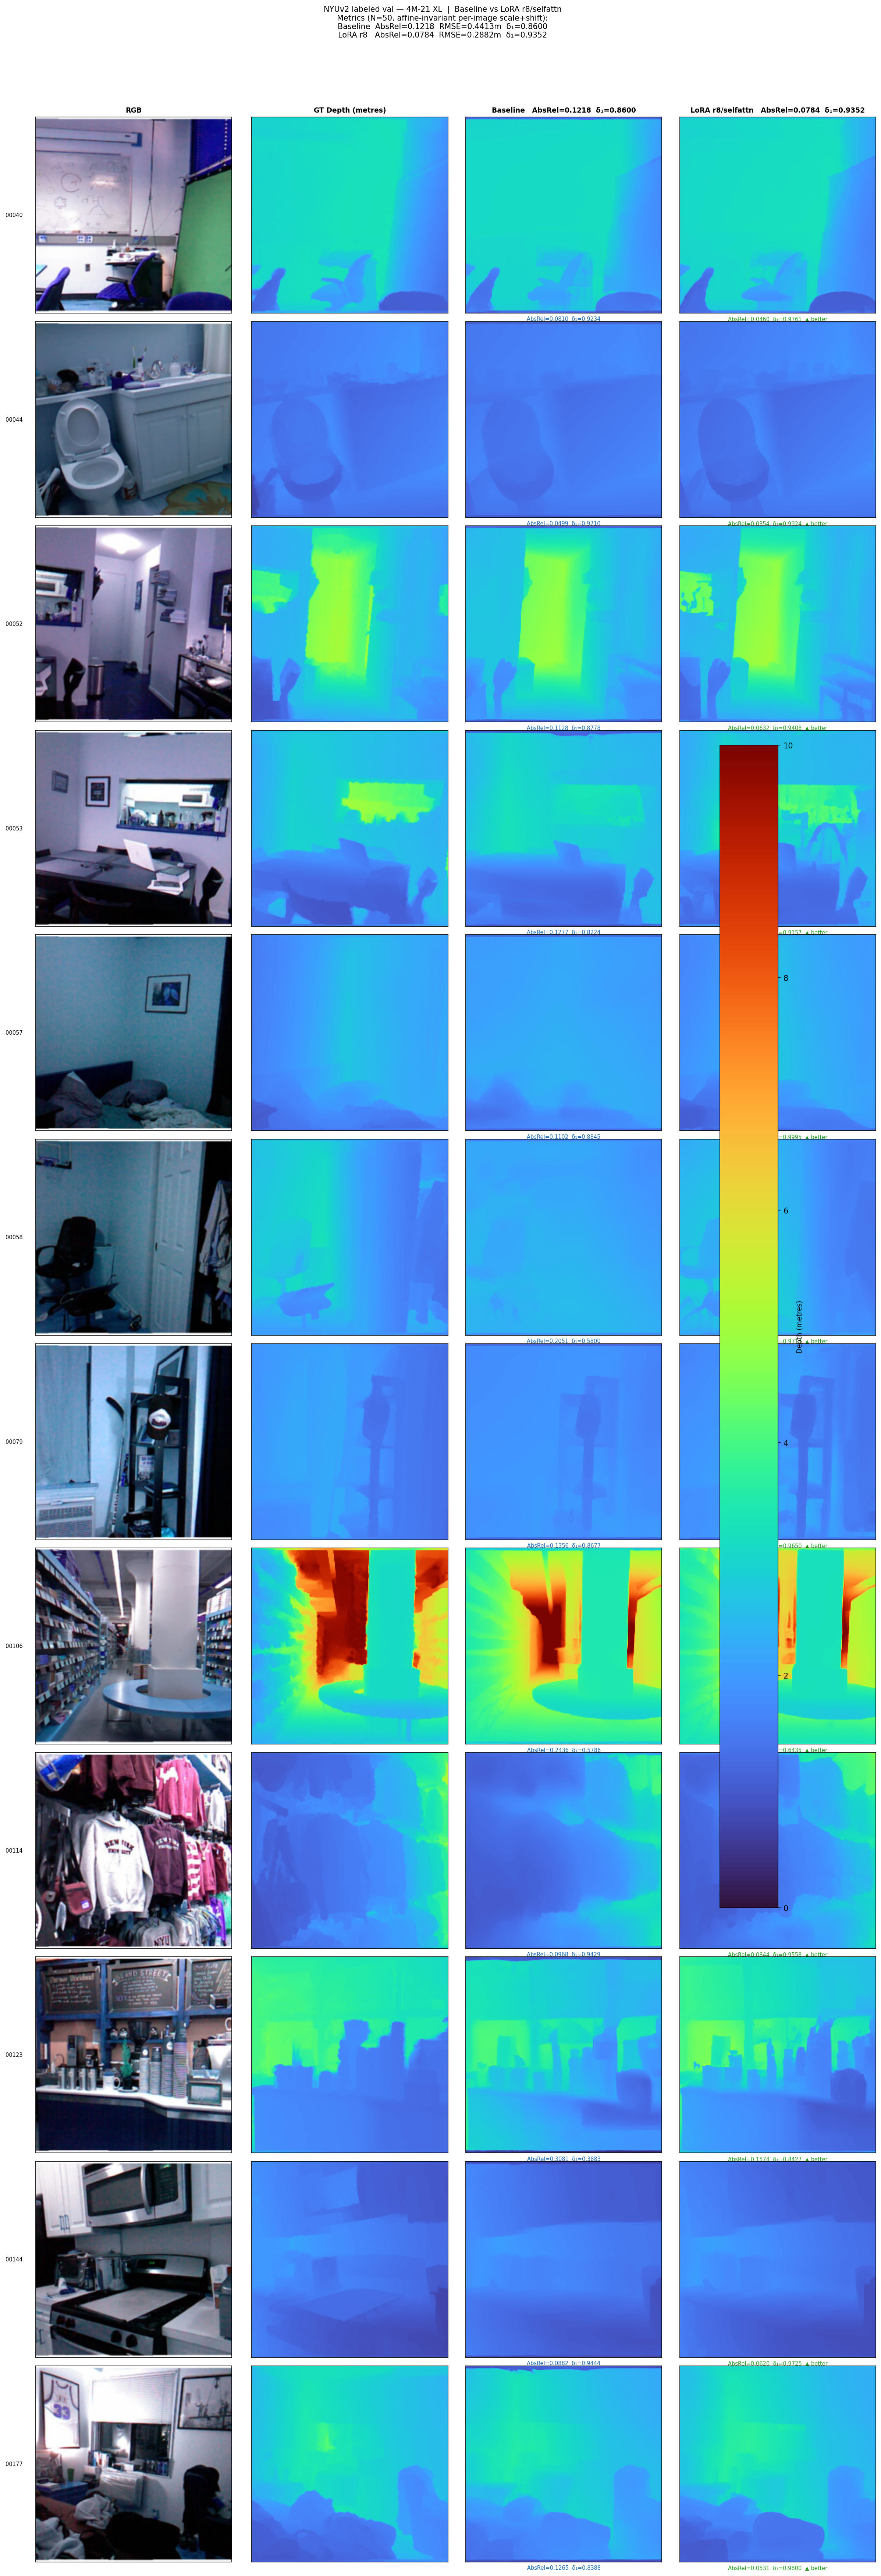

In [9]:
n_rows = N_VIZ
fig, axes = plt.subplots(n_rows, 4, figsize=(4 * 4, n_rows * 3.8))

col_titles = [
    'RGB',
    'GT Depth (metres)',
    f'Baseline   AbsRel={agg_base["abs_rel"]:.4f}  δ₁={agg_base["delta1"]:.4f}',
    f'LoRA r8/selfattn   AbsRel={agg_lora["abs_rel"]:.4f}  δ₁={agg_lora["delta1"]:.4f}',
]
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=9, fontweight='bold', pad=6)

for row, s in enumerate(viz_samples):
    gt_depth, valid = load_gt_depth(s['depth'])

    pred_b_aligned, *_ = scale_shift_align(preds_baseline[s['name']], gt_depth, valid)
    pred_l_aligned, *_ = scale_shift_align(preds_lora[s['name']],     gt_depth, valid)

    m_b = compute_metrics(pred_b_aligned, gt_depth, valid)
    m_l = compute_metrics(pred_l_aligned, gt_depth, valid)

    axes[row, 0].imshow(load_rgb_display(s['rgb']))
    axes[row, 1].imshow(colorise_depth(gt_depth))
    axes[row, 2].imshow(colorise_depth(pred_b_aligned))
    axes[row, 3].imshow(colorise_depth(pred_l_aligned))

    axes[row, 0].set_ylabel(s['name'], fontsize=7, rotation=0, labelpad=28, va='center')

    better_absrel = m_l['abs_rel'] < m_b['abs_rel']
    axes[row, 2].set_xlabel(
        f'AbsRel={m_b["abs_rel"]:.4f}  δ₁={m_b["delta1"]:.4f}',
        fontsize=7, color='#1a6bb5')
    axes[row, 3].set_xlabel(
        f'AbsRel={m_l["abs_rel"]:.4f}  δ₁={m_l["delta1"]:.4f}  '
        f'{"▲ better" if better_absrel else "▼ worse"}',
        fontsize=7, color='#2a9d2a' if better_absrel else '#c0392b')

    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])

# Colorbar
sm = plt.cm.ScalarMappable(cmap='turbo', norm=plt.Normalize(0, MAX_DEPTH))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes[:, 1:].ravel().tolist(), shrink=0.6, pad=0.02)
cbar.set_label('Depth (metres)', fontsize=9)

fig.suptitle(
    f'NYUv2 labeled val — 4M-21 XL  |  Baseline vs LoRA r8/selfattn\n'
    f'Metrics (N={len(metrics_base_list)}, affine-invariant per-image scale+shift):\n'
    f'Baseline  AbsRel={agg_base["abs_rel"]:.4f}  RMSE={agg_base["rmse"]:.4f}m  '
    f'δ₁={agg_base["delta1"]:.4f}\n'
    f'LoRA r8   AbsRel={agg_lora["abs_rel"]:.4f}  RMSE={agg_lora["rmse"]:.4f}m  '
    f'δ₁={agg_lora["delta1"]:.4f}',
    fontsize=10, y=1.02,
)
plt.tight_layout()

out_path = os.path.join(FIGURES_DIR, 'depth_comparison_r8_labeled.png')
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f'\nFigure saved → {out_path}')

try:
    from IPython.display import display, Image as IPImage
    display(IPImage(out_path))
except Exception:
    pass